# ME672 Assignment 3: Timber roof frame, plane-stress FE model
Units: m, N, Pa throughout.

## 1. Preamble

In [19]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpi4py import MPI

import gmsh
import pyvista
from pyvista.core.errors import PyVistaDeprecationWarning

import dolfinx
from dolfinx import default_scalar_type, mesh
from dolfinx.io import gmsh as gmshio
from dolfinx.fem import (Constant, Expression, Function, functionspace,
                         locate_dofs_topological, dirichletbc, form, assemble_scalar)
from dolfinx.fem.petsc import LinearProblem
from dolfinx.plot import vtk_mesh
from ufl import (TestFunction, TrialFunction, Measure, FacetNormal,
                 inner, dot, grad, sym, tr, sqrt, Identity, as_vector)

from fem_utils import (plot_errors, plot_sparseness, generate_error_table_general)

warnings.filterwarnings("ignore", category=PyVistaDeprecationWarning, module="pyvista")
print("DOLFINx", dolfinx.__version__)

DOLFINx 0.12.0.dev0


## 2. Parameters

In [ ]:
# geometry / section
b = 0.076            # out-of-plane thickness, m
s = 3.0              # roof width carried by one frame, m
y_bot = -0.143       # lower face of the 286 mm bottom chord, m

# material (assigned isotropic values)
E, nu = 10e9, 0.30
rho, g = 500.0, 9.81 #350 - Pine; 770 - Oak;
f_t, f_c, f_s = 5e6, 5e6, 1e6

# mesh
h = 0.03             # element size, m  (convergence study: e.g. 0.08, 0.05, 0.03)
element_order = 2
brep_file = "Timber_Frame_Rebuilt-Frame_Solid.brep"

## 3. Mesh (gmsh → DOLFINx)

In [21]:
gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
gmsh.model.add("frame")
occ = gmsh.model.occ

occ.importShapes(brep_file)
occ.dilate(occ.getEntities(), 0, 0, 0, 1e-3, 1e-3, 1e-3)    # mm -> m
occ.synchronize()

# points at the inner ends of the 100 mm support segments
p1 = occ.addPoint(0.05, y_bot, 0)
p2 = occ.addPoint(7.95, y_bot, 0)
surf = gmsh.model.getEntities(2)[0]
occ.fragment([surf], [(0, p1), (0, p2)])
occ.synchronize()
h_sup = 0.005            # element size at the support ends (try 0.01, 0.005, 0.0025)

sup_pts = []
for (x0, y0) in [(-0.05, y_bot), (0.05, y_bot), (7.95, y_bot), (8.05, y_bot)]:
    found = gmsh.model.getEntitiesInBoundingBox(x0-1e-6, y0-1e-6, -1, x0+1e-6, y0+1e-6, 1, dim=0)
    sup_pts += [t for _, t in found]
print("support points found:", len(sup_pts))      # expect 4

fd = gmsh.model.mesh.field.add("Distance")
gmsh.model.mesh.field.setNumbers(fd, "PointsList", sup_pts)
ft = gmsh.model.mesh.field.add("Threshold")
gmsh.model.mesh.field.setNumber(ft, "InField", fd)
gmsh.model.mesh.field.setNumber(ft, "SizeMin", h_sup)
gmsh.model.mesh.field.setNumber(ft, "SizeMax", h)
gmsh.model.mesh.field.setNumber(ft, "DistMin", 0.02)
gmsh.model.mesh.field.setNumber(ft, "DistMax", 0.30)
gmsh.model.mesh.field.setAsBackgroundMesh(ft)
gmsh.option.setNumber("Mesh.MeshSizeFromPoints", 0)
gmsh.option.setNumber("Mesh.MeshSizeExtendFromBoundary", 0)
s_tag = gmsh.model.getEntities(2)[0][1]
gmsh.model.addPhysicalGroup(2, [s_tag], 1)
gmsh.option.setNumber("Mesh.MeshSizeMax", h)
gmsh.model.mesh.generate(2)
gmsh.model.mesh.setOrder(element_order)

mesh_data = gmshio.model_to_mesh(gmsh.model, MPI.COMM_WORLD, 0, gdim=2)
domain = mesh_data.mesh
gmsh.finalize()

tdim = domain.topology.dim
fdim = tdim - 1
print("cells:", domain.topology.index_map(tdim).size_global)

support points found: 4
cells: 14642


## 4. Boundary tags
11 left support · 12 right support · 21 roof left · 22 roof right

In [22]:
domain.topology.create_connectivity(fdim, tdim)

def left_support(x):
    return np.isclose(x[1], y_bot) & (x[0] <= 0.05 + 1e-9)

def right_support(x):
    return np.isclose(x[1], y_bot) & (x[0] >= 7.95 - 1e-9)

def roof(x):
    centreline = (4/3) * (1 - np.abs(x[0] - 4.0) / 4.0)
    return x[1] > centreline + 0.10


f_left  = mesh.locate_entities_boundary(domain, fdim, left_support)
f_right = mesh.locate_entities_boundary(domain, fdim, right_support)
f_roof  = mesh.locate_entities_boundary(domain, fdim, roof)
mid = mesh.compute_midpoints(domain, fdim, f_roof)
f_roofL, f_roofR = f_roof[mid[:, 0] < 4.0], f_roof[mid[:, 0] >= 4.0]

indices = np.hstack([f_left, f_right, f_roofL, f_roofR]).astype(np.int32)
values  = np.hstack([np.full(len(f_left), 11), np.full(len(f_right), 12),
                     np.full(len(f_roofL), 21), np.full(len(f_roofR), 22)]).astype(np.int32)
order = np.argsort(indices)
facet_tags = mesh.meshtags(domain, fdim, indices[order], values[order])

dx_ = Measure("dx", domain=domain)
ds_ = Measure("ds", domain=domain, subdomain_data=facet_tags)
n = FacetNormal(domain)

## 5. Mesh checks

In [23]:
one = Constant(domain, default_scalar_type(1.0))
I = lambda expr: domain.comm.allreduce(assemble_scalar(form(expr)), op=MPI.SUM)

area = I(one*dx_)
proj_L = I(abs(n[1])*ds_(21))
proj_R = I(abs(n[1])*ds_(22))
print(f"area {area:.5f} m^2  ->  V = {b*area:.5f} m^3")
print(f"supports {I(one*ds_(11)):.4f}, {I(one*ds_(12)):.4f} m   (expect 0.1000)")
print(f"roof projections {proj_L:.4f}, {proj_R:.4f} m")

area 4.78702 m^2  ->  V = 0.36381 m^3
supports 0.1000, 0.1000 m   (expect 0.1000)
roof projections 4.0500, 4.0500 m


/tmp/ipykernel_8219/466993508.py:6: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  plotter.show()


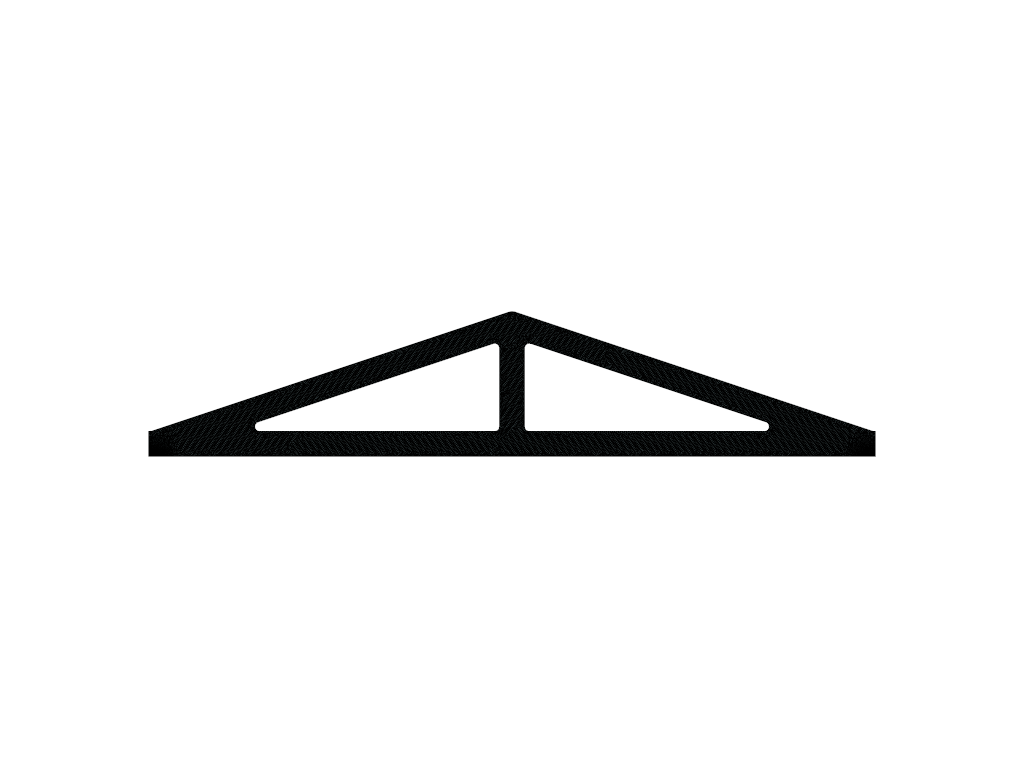

In [24]:
topology, cell_types, geometry = vtk_mesh(domain, tdim)
grid = pyvista.UnstructuredGrid(topology, cell_types, geometry)
plotter = pyvista.Plotter()
plotter.add_mesh(grid, show_edges=True)
plotter.view_xy()
plotter.show()

## 6. Function space and plane-stress constitutive law

In [25]:
V = functionspace(domain, ("Lagrange", element_order, (2,)))

mu = E/(2*(1+nu))
lmbda_ps = E*nu/(1-nu**2)          # plane stress

def epsilon(u):
    return sym(grad(u))

def sigma(u):
    return lmbda_ps*tr(epsilon(u))*Identity(2) + 2*mu*epsilon(u)

u = TrialFunction(V)
v = TestFunction(V)

## 7. Supports

In [26]:
dofs_L = locate_dofs_topological(V, fdim, facet_tags.find(11))
# TODO: right (tag 12): uy = 0 only  -> use V.sub(1) for both the dofs and dirichletbc
dofs_R = locate_dofs_topological(V.sub(1), fdim, facet_tags.find(12))
bc_L = dirichletbc(np.zeros(2, dtype=default_scalar_type), dofs_L, V)
bc_R = dirichletbc(default_scalar_type(0), dofs_R, V.sub(1))
bcs = [bc_L, bc_R]
print(len(dofs_L), len(dofs_R))

37 37


## 8. Loads and weak form

Number of degrees of freedom: 60790
Number of non-zeros: 1364852
Covering fraction: 0.04%


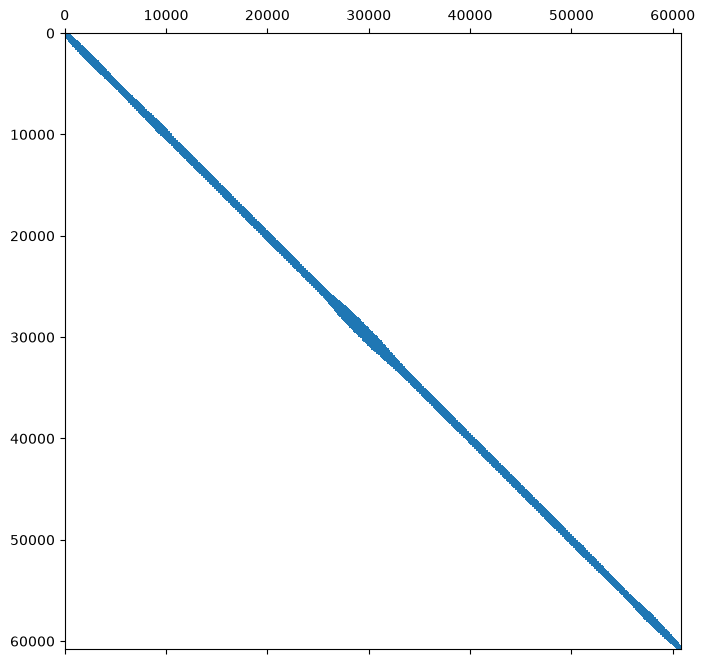

In [27]:
f_v = Constant(domain, default_scalar_type((0.0, -rho*g)))
pL = Constant(domain, default_scalar_type(0.0))   # Pa, left half
pR = Constant(domain, default_scalar_type(0.0))   # Pa, right half
q_L = as_vector((0.0, -pL*s*abs(n[1])))
q_R = as_vector((0.0, -pR*s*abs(n[1])))
a = b*inner(sigma(u), epsilon(v))*dx_
L = b*dot(f_v, v)*dx_ + dot(q_L, v)*ds_(21) + dot(q_R, v)*ds_(22)
#       (call the RHS form L, not b: b is the thickness)
plot_sparseness(a)

## 9. Load cases
All pressures in kPa, positive downward.

In [28]:
cases = {          # (p_left, p_right)
    "G":   (1.10, 1.10),
    "A":   (1.10, 0.35),
    "A_m": (0.35, 1.10),
    "U":   (-1.15, -1.15),
    "W":   (-1.15, 0.85),
    "W_m": (0.85, -1.15),
}

## 10. Solve

In [29]:
problem = LinearProblem(a, L, bcs=bcs, petsc_options_prefix="frame_",
                        petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
pL.value, pR.value = 1.10e3, 1.10e3      # case G, in Pa
uh = problem.solve()
print("max |ux|, |uy| [mm]:", 1e3*np.abs(uh.x.array[0::2]).max(), 1e3*np.abs(uh.x.array[1::2]).max())
# TODO: loop over cases: set pL.value, pR.value (x1e3 for Pa), solve, store uh

max |ux|, |uy| [mm]: 1.2913386264008424 3.1525036235938044


## 11. Equilibrium and energy checks

In [30]:
nodes_L = locate_dofs_topological(V, fdim, facet_tags.find(11))   # node indices
nodes_R = locate_dofs_topological(V, fdim, facet_tags.find(12))

def reaction(nodes, comp):            # comp 0 = x, 1 = y
    w = Function(V)
    w.x.array[2*nodes + comp] = 1.0
    work = b*inner(sigma(uh), epsilon(w))*dx_ \
         - (b*dot(f_v, w)*dx_ + dot(q_L, w)*ds_(21) + dot(q_R, w)*ds_(22))
    return I(work)


# TODO: reactions R = ∫ b σ(uh)·n ds_(11) and ds_(12)  -> compare with total load
#       total vertical load = rho*g*b*area + (pL*proj_L + pR*proj_R)*s
# TODO: 2U = f^T u :  U = 0.5*∫ b σ:ε dx ,  f^T u = L evaluated with v -> uh

## 12. Stresses and feasibility

In [31]:
W0 = functionspace(domain, ("DG", 1))          # stress lives here (it jumps between elements)
X  = W0.element.interpolation_points
xy = W0.tabulate_dof_coordinates()[:, :2]      # (x, y) of every stress value

# 50 mm exclusion zones around the four support-segment ends
ends = np.array([[-0.05, y_bot], [0.05, y_bot], [7.95, y_bot], [8.05, y_bot]])
dist = np.min(np.linalg.norm(xy[:, None, :] - ends[None, :, :], axis=2), axis=1)
excluded = dist < 0.05
print(f"{excluded.sum()} of {len(excluded)} stress points excluded")

def stress_component(uh, i, j):
    fh = Function(W0)
    fh.interpolate(Expression(sigma(uh)[i, j], X))
    return fh.x.array.copy()

def check_case(uh):
    sxx = stress_component(uh, 0, 0)
    syy = stress_component(uh, 1, 1)
    sxy = stress_component(uh, 0, 1)

    # principal stresses (sigma_3 = 0 out of plane)
    c  = (sxx + syy) / 2
    R  = np.sqrt(((sxx - syy) / 2)**2 + sxy**2)
    s1, s2 = c + R, c - R
    zero = np.zeros_like(s1)
    smax = np.maximum.reduce([zero, s1, s2])
    smin = np.minimum.reduce([zero, s1, s2])

    # the brief's three ratios (feasible if all <= 1)
    tens  = smax / f_t
    comp  = -smin / f_c
    shear = (smax - smin) / 2 / f_s

    keep = ~excluded
    ux, uy = uh.x.array[0::2], uh.x.array[1::2]
    return {
        "max_ux_mm": 1e3*np.abs(ux).max(),
        "max_uy_mm": 1e3*np.abs(uy).max(),
        "tension":     tens[keep].max(),
        "compression": comp[keep].max(),
        "shear":       shear[keep].max(),
        "tension_excl":     tens[excluded].max(),     # reported separately
        "compression_excl": comp[excluded].max(),
        "shear_excl":       shear[excluded].max(),
    }



2333 of 43926 stress points excluded


In [32]:
rows = []
for case, (p_l, p_r) in cases.items():
    pL.value, pR.value = p_l*1e3, p_r*1e3
    uh = problem.solve()

    W_tot = rho*g*b*area + (pL.value*proj_L + pR.value*proj_R)*s
    Ry_L, Ry_R = reaction(nodes_L, 1), reaction(nodes_R, 1)
    Rx_L, Rx_R = reaction(nodes_L, 0), reaction(nodes_R, 0)
    U  = 0.5*I(b*inner(sigma(uh), epsilon(uh))*dx_)
    fu = I(b*dot(f_v, uh)*dx_ + dot(q_L, uh)*ds_(21) + dot(q_R, uh)*ds_(22))

    print(f"{case:4s} load {W_tot/1e3:8.3f} kN | Ry sum {(Ry_L+Ry_R)/1e3:8.3f} kN | "
          f"Rx {Rx_L:.1e}, {Rx_R:.1e} N | 2U-fu rel {abs(2*U-fu)/abs(fu):.1e}")

    row = check_case(uh)
    row.update({"case": case, "load_kN": W_tot/1e3,
                "Ry_L_kN": Ry_L/1e3, "Ry_R_kN": Ry_R/1e3, "U_J": U})
    rows.append(row)

G    load   28.515 kN | Ry sum   28.515 kN | Rx -4.0e-08, 3.3e-09 N | 2U-fu rel 5.8e-13
A    load   19.402 kN | Ry sum   19.402 kN | Rx -4.1e-09, 2.0e-09 N | 2U-fu rel 4.2e-12
A_m  load   19.402 kN | Ry sum   19.402 kN | Rx -5.0e-08, 1.6e-09 N | 2U-fu rel 3.5e-12
U    load  -26.160 kN | Ry sum  -26.160 kN | Rx 3.6e-08, -1.9e-09 N | 2U-fu rel 3.5e-13
W    load   -1.860 kN | Ry sum   -1.860 kN | Rx -5.9e-08, -7.0e-11 N | 2U-fu rel 1.3e-12
W_m  load   -1.860 kN | Ry sum   -1.860 kN | Rx 6.4e-08, -1.2e-10 N | 2U-fu rel 4.0e-12


In [33]:
df = pd.DataFrame(rows).set_index("case")
df["feasible"] = ((df[["tension", "compression", "shear"]] <= 1).all(axis=1)
                  & (df["max_ux_mm"] <= 33.3) & (df["max_uy_mm"] <= 33.3))
df.to_csv("results_baseline.csv")
df.round(3)

,max_ux_mm,max_uy_mm,tension,compression,shear,tension_excl,compression_excl,shear_excl,load_kN,Ry_L_kN,Ry_R_kN,U_J,feasible
case,,,,,,,,,,,,,
G,1.291,3.153,1.705,1.368,4.262,5.096,18.890,47.226,28.515,14.277,14.238,32.268,False
A,1.026,2.743,1.365,1.206,3.413,4.491,16.544,41.359,19.402,12.134,7.268,16.581,False
A_m,0.890,2.767,1.507,1.217,3.768,3.790,12.597,31.493,19.402,7.294,12.108,16.691,False
U,1.176,2.903,1.297,1.554,3.885,17.246,4.647,43.115,-26.160,-13.098,-13.062,27.070,False
W,0.758,1.889,1.323,1.260,3.370,10.989,6.535,27.472,-1.860,-7.385,5.524,12.085,False
W_m,0.685,1.910,1.321,1.265,3.329,8.346,8.618,21.544,-1.860,5.522,-7.382,12.112,False


## 13. Plots

/tmp/ipykernel_8219/443036365.py:38: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  p.show(screenshot=f"deformed_{plot_case}.png")


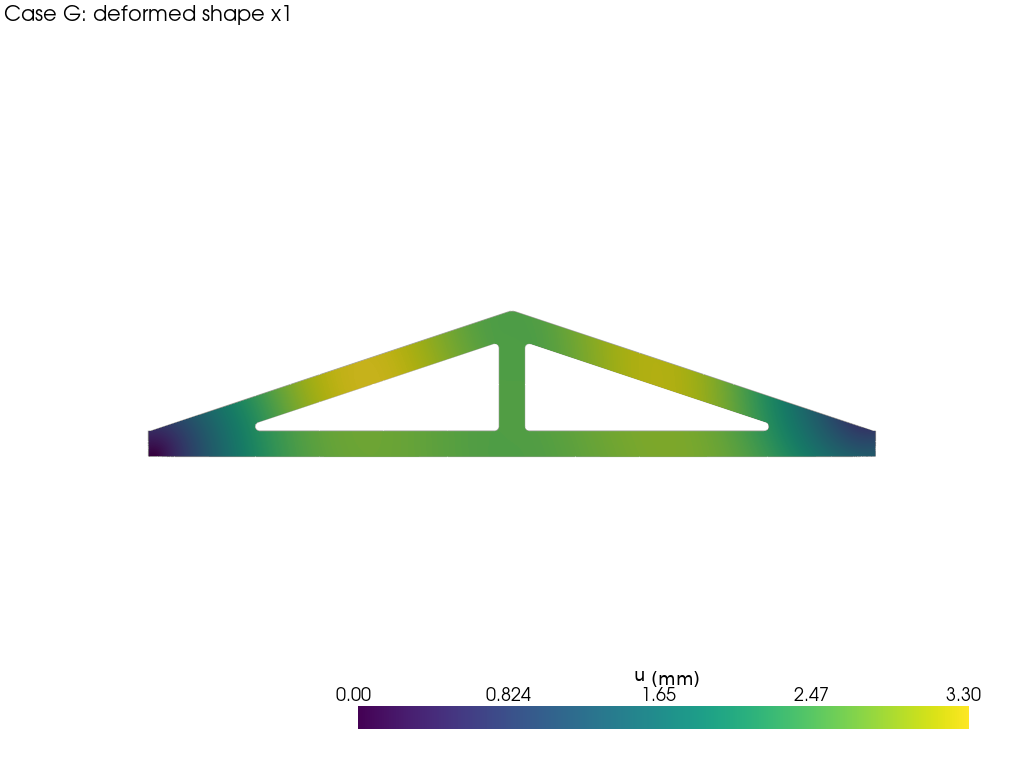

/tmp/ipykernel_8219/443036365.py:53: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  p.show(screenshot=f"shear_{plot_case}.png")


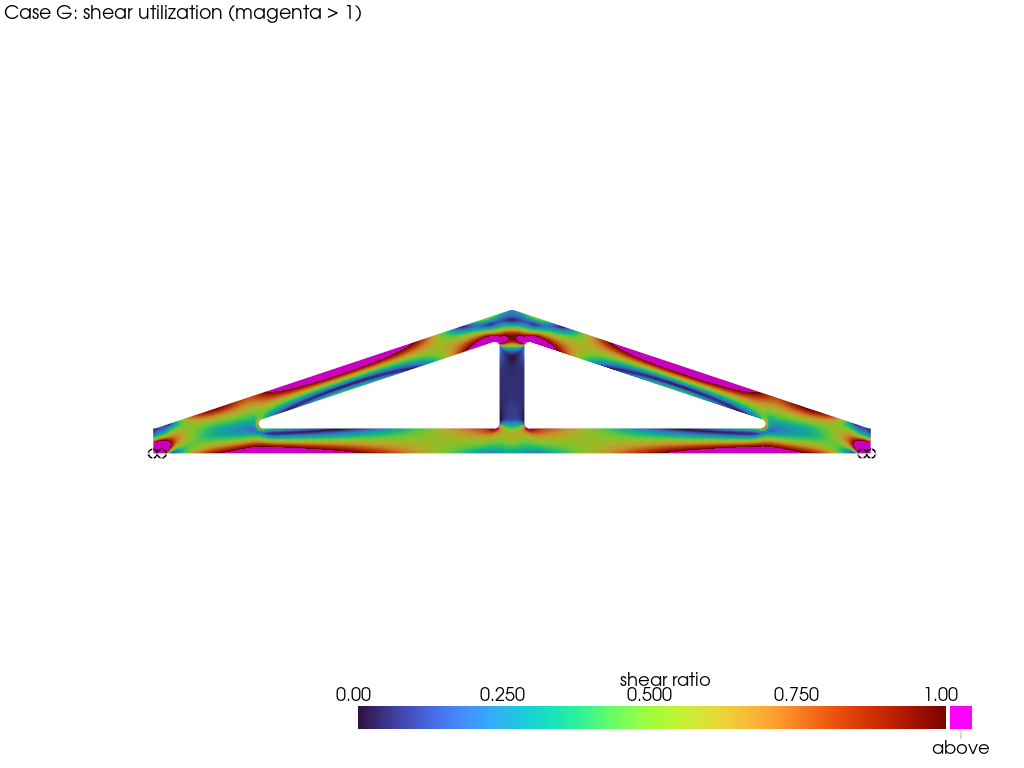

max shear ratio 4.26 at x = 8.050 m, y = -0.093 m


/tmp/ipykernel_8219/443036365.py:66: UserWarning: Using static image for notebook display.
Install trame for interactive backends: pip install pyvista[jupyter]
  p.show(screenshot=f"shear_zoom_{plot_case}.png")


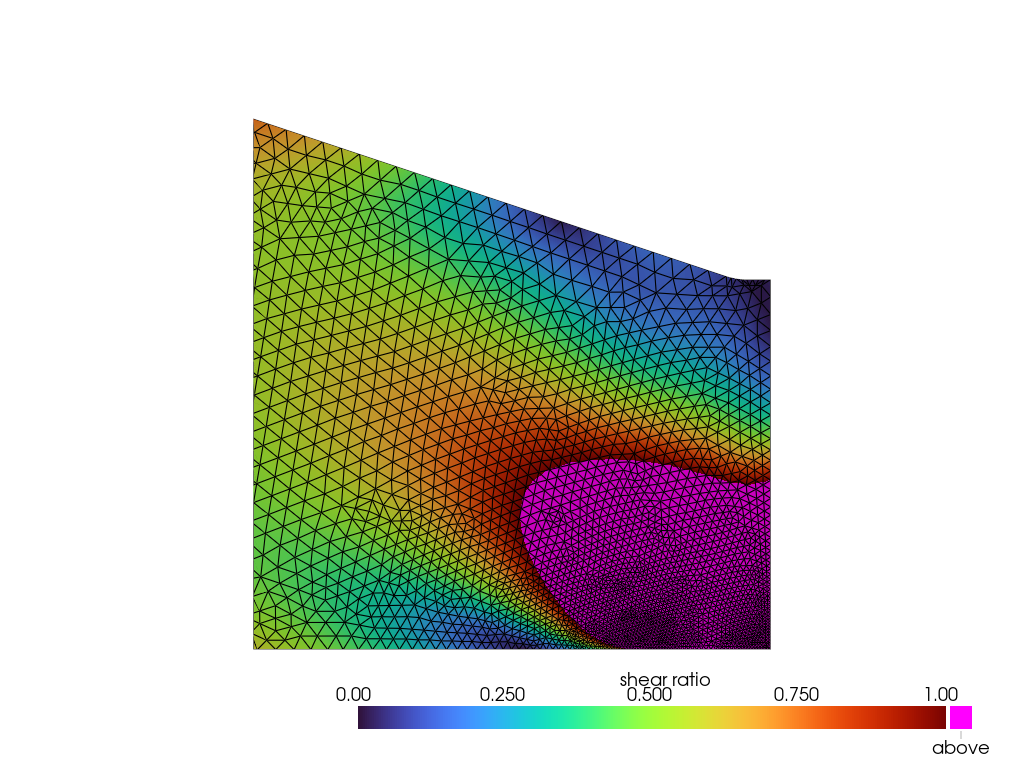

In [34]:
plot_case = "G"                                   # change to "U", "W", ...
pL.value, pR.value = np.array(cases[plot_case]) * 1e3
uh = problem.solve()

# DG2 for plotting: matches the curved (P2) mesh geometry, so pyvista accepts it
Wp = functionspace(domain, ("DG", 2))
Xp = Wp.element.interpolation_points

def field(expr):
    fh = Function(Wp)
    fh.interpolate(Expression(expr, Xp))
    return fh.x.array.copy()

S = sigma(uh)
sxx, syy, sxy = field(S[0, 0]), field(S[1, 1]), field(S[0, 1])
c = (sxx + syy)/2
R = np.sqrt(((sxx - syy)/2)**2 + sxy**2)
s1, s2 = c + R, c - R
zero = np.zeros_like(s1)
smax = np.maximum.reduce([zero, s1, s2])
smin = np.minimum.reduce([zero, s1, s2])
shear_ratio = (smax - smin)/2/f_s
tension_ratio = smax/f_t
comp_ratio = -smin/f_c

topo, ctypes, geom = vtk_mesh(V)
grid_u = pyvista.UnstructuredGrid(topo, ctypes, geom)
u3 = np.zeros((geom.shape[0], 3))
u3[:, :2] = uh.x.array.reshape(-1, 2)
grid_u["|u| (mm)"] = 1e3*np.linalg.norm(u3, axis=1)
grid_u["u"] = u3

p = pyvista.Plotter()
p.add_mesh(grid_u, style="wireframe", color="lightgray")           # undeformed
p.add_mesh(grid_u.warp_by_vector("u", factor=1), scalars="|u| (mm)", cmap="viridis")
p.add_text(f"Case {plot_case}: deformed shape x1", font_size=10)
p.view_xy()
p.show(screenshot=f"deformed_{plot_case}.png")
topo, ctypes, geom = vtk_mesh(Wp)
grid_s = pyvista.UnstructuredGrid(topo, ctypes, geom)
grid_s["shear ratio"] = shear_ratio
grid_s["tension ratio"] = tension_ratio
grid_s["compression ratio"] = comp_ratio

p = pyvista.Plotter()
p.add_mesh(grid_s, scalars="shear ratio", cmap="turbo", clim=[0, 1],
           above_color="magenta", scalar_bar_args={"title": "shear ratio"})
for (x0, y0) in ends:                                               # 50 mm exclusion circles
    p.add_mesh(pyvista.Circle(radius=0.05).translate((x0, y0, 0.01)),
               style="wireframe", color="black", line_width=2)
p.add_text(f"Case {plot_case}: shear utilization (magenta > 1)", font_size=10)
p.view_xy()
p.show(screenshot=f"shear_{plot_case}.png")
xy_p = Wp.tabulate_dof_coordinates()[:, :2]
d_ends = np.min(np.linalg.norm(xy_p[:, None, :] - ends[None, :, :], axis=2), axis=1)
outside = d_ends >= 0.05
i = np.argmax(np.where(outside, shear_ratio, -np.inf))
x0, y0 = xy_p[i]
print(f"max shear ratio {shear_ratio[i]:.2f} at x = {x0:.3f} m, y = {y0:.3f} m")

zoom = grid_s.clip_box((x0-0.4, x0+0.4, y0-0.4, y0+0.4, -1, 1), invert=False)
p = pyvista.Plotter()
p.add_mesh(zoom, scalars="shear ratio", cmap="turbo", clim=[0, 1],
           above_color="magenta", show_edges=True)
p.view_xy()
p.show(screenshot=f"shear_zoom_{plot_case}.png")

## 14. Results table

In [35]:
# TODO: one row per case: max |u|, stress ratios, reactions, feasible?  -> pandas DataFrame -> CSV
results = []

for case, (p_l, p_r) in cases.items():
    # 1. Update roof loads (convert kPa to Pa) and solve FE problem
    pL.value, pR.value = p_l * 1e3, p_r * 1e3
    uh = problem.solve()

    # 2. Compute total applied vertical load and support reactions
    W_tot = rho * g * b * area + (pL.value * proj_L + pR.value * proj_R) * s
    Rx_L, Ry_L = reaction(nodes_L, 0), reaction(nodes_L, 1)
    Rx_R, Ry_R = reaction(nodes_R, 0), reaction(nodes_R, 1)

    # 3. Compute strain energy (U) and external work (f^T u)
    U  = 0.5 * I(b * inner(sigma(uh), epsilon(uh)) * dx_)
    fu = I(b * dot(f_v, uh) * dx_ + dot(q_L, uh) * ds_(21) + dot(q_R, uh) * ds_(22))

    # 4. Evaluate max displacements and stress ratios (outside & inside exclusion zones)
    row = check_case(uh)

    # 5. Append reaction and energy metrics to the row dictionary
    row.update({
        "case": case,
        "load_kN": W_tot / 1e3,
        "Rx_L_N": Rx_L,
        "Ry_L_kN": Ry_L / 1e3,
        "Rx_R_N": Rx_R,
        "Ry_R_kN": Ry_R / 1e3,
        "U_J": U,
        "energy_rel_err": abs(2 * U - fu) / abs(fu),
    })
    results.append(row)

# Build DataFrame and check design feasibility criteria
df_results = pd.DataFrame(results).set_index("case")
df_results["feasible"] = (
    (df_results[["tension", "compression", "shear"]] <= 1.0).all(axis=1)
    & (df_results["max_ux_mm"] <= 33.3)
    & (df_results["max_uy_mm"] <= 33.3)
)

# Save to CSV and display rounded table
df_results.to_csv("results_summary.csv")
df_results.round(3)


,max_ux_mm,max_uy_mm,tension,compression,shear,tension_excl,compression_excl,shear_excl,load_kN,Rx_L_N,Ry_L_kN,Rx_R_N,Ry_R_kN,U_J,energy_rel_err,feasible
case,,,,,,,,,,,,,,,,
G,1.291,3.153,1.705,1.368,4.262,5.096,18.890,47.226,28.515,-0.0,14.277,0.0,14.238,32.268,0.0,False
A,1.026,2.743,1.365,1.206,3.413,4.491,16.544,41.359,19.402,-0.0,12.134,0.0,7.268,16.581,0.0,False
A_m,0.890,2.767,1.507,1.217,3.768,3.790,12.597,31.493,19.402,-0.0,7.294,0.0,12.108,16.691,0.0,False
U,1.176,2.903,1.297,1.554,3.885,17.246,4.647,43.115,-26.160,0.0,-13.098,-0.0,-13.062,27.070,0.0,False
W,0.758,1.889,1.323,1.260,3.370,10.989,6.535,27.472,-1.860,-0.0,-7.385,-0.0,5.524,12.085,0.0,False
W_m,0.685,1.910,1.321,1.265,3.329,8.346,8.618,21.544,-1.860,0.0,5.522,-0.0,-7.382,12.112,0.0,False


In [36]:
# 1. Setup PyVista mesh data for 2D deformed shape plots
topo, ctypes, geom = vtk_mesh(V)
scale_factor = 1  # magnification for visibility

# 2. Setup bottom-chord node coordinates for 1D deflection curve plots
coords = V.tabulate_dof_coordinates()[:, :2]
bot_mask = np.isclose(coords[:, 1], y_bot, atol=1e-6)
bot_indices = np.where(bot_mask)
sort_order = np.argsort(coords[bot_indices, 0])
bot_indices = bot_indices[sort_order]
x_span = coords[bot_indices, 0]

# Initialize Matplotlib figure for the combined bottom-chord profiles
fig, ax = plt.subplots(figsize=(10, 5))

# 3. Single loop through all load cases
for case, (p_l, p_r) in cases.items():
    # Update loads (kPa -> Pa) and solve once per case
    pL.value, pR.value = p_l * 1e3, p_r * 1e3
    uh = problem.solve()

    # --- A. 2D PyVista Deformed Shape Plot ---
    grid_u = pyvista.UnstructuredGrid(topo, ctypes, geom)
    u3 = np.zeros((geom.shape, 3))
    u3[:, :2] = uh.x.array.reshape(-1, 2)
    grid_u["|u| (mm)"] = 1e3 * np.linalg.norm(u3, axis=1)
    grid_u["u"] = u3

    p = pyvista.Plotter(off_screen=True)
    p.add_mesh(grid_u, style="wireframe", color="lightgray")
    p.add_mesh(
        grid_u.warp_by_vector("u", factor=scale_factor),
        scalars="|u| (mm)",
        cmap="viridis",
        scalar_bar_args={"title": "|u| [mm]"},
    )
    p.add_text(f"Case {case}: deformed shape (x{scale_factor})", font_size=10)
    p.view_xy()
    p.screenshot(f"deformed_{case}.png")
    p.close()

    # --- B. 1D Bottom-Chord Deflection Curve ---
    u_xy = uh.x.array.reshape(-1, 2)
    uy_mm = 1e3 * u_xy[bot_indices, 1]
    ax.plot(x_span, uy_mm, label=f"Case {case} (max |uy| = {np.abs(uy_mm).max():.2f} mm)")

# 4. Finalize and save the combined Matplotlib comparison chart
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")
ax.axhline(-33.3, color="red", linewidth=0.8, linestyle=":", label="Deflection limit (±33.3 mm)")
ax.axhline(33.3, color="red", linewidth=0.8, linestyle=":")

ax.set_title("Bottom Chord Vertical Deflection Profile Across Load Cases")
ax.set_xlabel("Span position x [m]")
ax.set_ylabel("Vertical deflection uy [mm]")
ax.grid(True, alpha=0.3)
ax.legend(loc="best")
plt.tight_layout()
plt.savefig("deflection_profiles_all_cases.png", dpi=200)
plt.show()

print("Saved individual 2D deformed plots and combined deflection_profiles_all_cases.png.")



TypeError: only integer scalar arrays can be converted to a scalar index